# 5-closed-loop: cruise friction

Refit the friction line the velocity loop feeds forward on mg90-d, from Velocity cruises run with the window term of the window-term notebook taken off every reading, so the set's two friction words come from a notebook. Depends on stage 3 window-term.

## Purpose

The velocity loop adds a friction feed-forward to its current reference once a MEDIUM period, ten control ticks, as a line in speed,

$$i_\mathrm{ff} = f_c + f_v\,|\omega|,$$

with $f_c$ ("f c") the Coulomb term in shunt counts, $f_v$ ("f v") the viscous term per count/s and $\omega$ ("omega") the speed in counts of the position table a second. What the line misses, the loop's integrator carries. A line that matches leaves the integrator near zero at every speed, so the loop does not have to wind up its integral before it holds a cruise.

The line the loop needs is the current it holds while cruising, in its own reading, with the window term taken off that reading. That is not the drag as a torque that stage 3's friction notebook measured open loop, since at a slow cruise many ticks give no reading and the loop holds its reference there instead.

The loop's current is not one number a tick. On a tick whose drive window is at or over the board's current floor, 64 ticks, there is a reading and the current loop's PI acts on it, a read row. Under the floor there is no reading, and the current loop applies the volts of its reference open loop, an unread row. The held mean is the mean over a leg's steady rows of the reading on read rows and the reference on unread ones, what the loop carries as current on every tick. The integrator's share is the reference's mean less the line at the goal.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import constants as cn, figures, results, scales, servos
from oscnb import windowterm as wt
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED
from oscnb.speed import ALPHA_CU

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo
BOARD_KEY = "dev-v006-2A-D"             # the board, checked on every leg
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
DATA = (Path("../../../telemetry") / PAIR / "window-term").resolve()
RUNS = {"g3": DATA / "g3", "g3b": DATA / "g3b"}   # the two sittings
SPEEDS = ("c300", "c800", "c1500", "c4025")       # a capture a goal speed
G1 = DATA / "g1" / "ol-1"               # onsets with the board's reading
for name, folder in RUNS.items():
    print(name, "from", results.rel(folder), SPEEDS)
print("reading check from", results.rel(G1))

g3 from telemetry/mg90-d__dev-v006-2A-D/window-term/g3 ('c300', 'c800', 'c1500', 'c4025')
g3b from telemetry/mg90-d__dev-v006-2A-D/window-term/g3b ('c300', 'c800', 'c1500', 'c4025')
reading check from telemetry/mg90-d__dev-v006-2A-D/window-term/g1/ol-1


### The set of record

The cruises' speeds are counts of the set's position table, the pot through the board's wide-code slots and the table. The set of record gives the table, the current loop's gains, the back-EMF word $K_e$ ("K e") the current loop feeds forward and the inertia word. Its current scale is stage 1's, checked.

In [3]:
DOC, FIELDS, TABLE, SLOTS = wt.set_tables(PAIR)   # the set of record
CPA = DOC["scales"][cn.CURRENT]["value"]   # shunt counts per A
MA = 1e3 / CPA                          # mA a shunt count
KE_VPC = FIELDS["ke_vpc_q"] / 4096      # tap counts per count/s, Ke
J_FF = FIELDS["j_ff_q88"] / 256         # shunt counts per (c/s)/tick
GEAR = DOC["inputs"]["registry"]["servo"]["gear_ratio"]
COUNTS_PER_DEG = DOC["scale"]["counts_per_deg"]   # the table's counts
COUNTS_PER_MOTOR_RAD = COUNTS_PER_DEG * 180 / math.pi / GEAR
SCALES = scales.load(BOARD_KEY)         # stage 1's lines
assert SCALES.counts_per_a == CPA       # the set scores with stage 1's
print(f"{CPA:.3f} counts/A ({MA:.4f} mA a count), Ke {KE_VPC:.4f} tap "
      f"counts per c/s, j_ff {J_FF:.3f}, table {COUNTS_PER_DEG:.4f} counts "
      f"a degree, gear {GEAR}:1, {COUNTS_PER_MOTOR_RAD:.4f} counts a motor "
      f"radian")

1135.013 counts/A (0.8810 mA a count), Ke 0.0769 tap counts per c/s, j_ff 3.367, table 20.1266 counts a degree, gear 308.0533:1, 3.7434 counts a motor radian


### The window term

Stage 3 window-term's term over the period's mean, as the field it gives on stage 1's two scales. The sittings below are checked to have run on exactly this field.

In [4]:
WT = results.read("3-servo", "window-term", pair=PAIR)
G_MEAN = WT["g_over_mean_ms"]           # mS, the term over the mean
FIELD = round(G_MEAN["value"] * 1e-3 * CPA
              / SCALES.terminal_counts_per_v * 65536)
print(f"window term {G_MEAN['value']:.3f} mS ({G_MEAN['lo']:.3f} to "
      f"{G_MEAN['hi']:.3f}), g_window_q016 {FIELD} on stage 1's scales")

window term 3.933 mS (3.891 to 3.974), g_window_q016 1178 on stage 1's scales


The constants of the method, each with its unit and reason. The copper slope is `oscnb.speed`'s.

In [5]:
STEADY_CUT = 4      # a leg's steady rows: its middle half, a quarter cut
TRAVEL_COUNTS = 60  # counts of travel a speed window spans at the goal
SPEED_WINDOW_MIN_S = 0.02   # s, never shorter: the pot's own steps
SPEED_TOL = 0.05    # share of the goal a window must hold to count as held
STEADY_TOP_PCT = 2  # %, the 4025 leg whose speed held across its steady
                    # rows within this, the one leg at the top taken
COPPER = ALPHA_CU   # per C, copper's slope, r_hat followed to each leg

## Procedure

Two sittings on one image, horn free, 5 V, the window term installed at the window-term notebook's field.

- `g3`, with the friction words 40 / 728 installed. Velocity mode, goals of +/-300 c/s in six legs of 1.2 s, +/-800 in six of 1.2 s, +/-1500 in six of 0.9 s, each leg reversing the last, then -4025 for 250 ms, +4025 and -4025 for 500 ms each and +4025 for 250 ms. A zero goal ends each capture and torque goes off between captures.
- `g3b`, after the sitting set the words to the refit 43 / 947, saved them and rebooted. The same legs at 300 to 1500 c/s, and at 4025 six whole legs of 600 ms between two of 300 ms.

`g3` is the capture the line is fitted on. `g3b` is the repeat that grades it.

## Data

### fields.json

Each sitting's read of the servo's fields with torque off before its first cruise, from the sitting's log. The window field, the friction words and the winding resistance `r_hat_q12` at the sitting's start are in no row and no `meta.json`, and the replay below needs all three. `g3b` holds the two words it set and read back after the save.

In [6]:
SITTING = {name: wt.sitting_fields(folder) for name, folder in RUNS.items()}
for name, f in SITTING.items():
    print(f"{name}: g_window_q016 {f['g_window_q016']}, friction "
          f"{f['fric_fc_counts']} / {f['fric_fv_q016']}, r_hat_q12 "
          f"{f['r_hat_q12']}, velocity_limit_cps {f['velocity_limit_cps']},"
          f" write_late_count {f['write_late_count']}")
    assert f["g_window_q016"] == FIELD  # the window-term notebook's value

g3: g_window_q016 1178, friction 40 / 728, r_hat_q12 3676, velocity_limit_cps 4025, write_late_count 0
g3b: g_window_q016 1178, friction 43 / 947, r_hat_q12 3676, velocity_limit_cps 4025, write_late_count 0


### meta.json

Each capture's meta carries the board's sense block, the plant stamp, the servo's loop gains and limits, and the schedule of goals. The current loop's gains are checked against the set's, and the move speed limit against the sitting's read. A capture off the live table or with dropped rows is refused.

In [7]:
CAPS = {name: {s: wt.load_track(folder / s, TABLE, SLOTS) for s in SPEEDS}
        for name, folder in RUNS.items()}
for name, caps in CAPS.items():
    for s, cap in caps.items():
        m, cfg = cap["meta"], cap["meta"]["config"]
        assert (cfg["i_kp_q88"], cfg["i_ki_q412"]) == (
            FIELDS["i_kp_q88"], FIELDS["i_ki_q412"])   # the set's gains
        assert cfg["velocity_limit_cps"] == SITTING[name][
            "velocity_limit_cps"]
        print(f"{name} {s}: {m['plant']['plant_stamp']}, {len(cap['rows'])}"
              f" rows, i_kp {cfg['i_kp_q88']} i_ki {cfg['i_ki_q412']}, "
              f"{m['schedule']}")
BOARD = CAPS["g3"]["c300"]["board"]     # identified from the sense block
t0 = {n: c["c300"]["polls"].loc[0, "t_start"] for n, c in CAPS.items()}
print(f"g3b's first leg {(t0['g3b'] - t0['g3']) / 60:.1f} minutes after "
      f"g3's, by the host's clock")

g3 c300: 0x4639, 152000 rows, i_kp 289 i_ki 1176, ['goal:300@1200', 'goal:-300@1200', 'goal:300@1200', 'goal:-300@1200', 'goal:300@1200', 'goal:-300@1200', 'goal:0@400']
g3 c800: 0x4639, 152000 rows, i_kp 289 i_ki 1176, ['goal:800@1200', 'goal:-800@1200', 'goal:800@1200', 'goal:-800@1200', 'goal:800@1200', 'goal:-800@1200', 'goal:0@400']
g3 c1500: 0x4639, 116000 rows, i_kp 289 i_ki 1176, ['goal:1500@900', 'goal:-1500@900', 'goal:1500@900', 'goal:-1500@900', 'goal:1500@900', 'goal:-1500@900', 'goal:0@400']
g3 c4025: 0x4639, 38000 rows, i_kp 289 i_ki 1176, ['goal:-4025@250', 'goal:4025@500', 'goal:-4025@500', 'goal:4025@250', 'goal:0@400']
g3b c300: 0xec1d, 152000 rows, i_kp 289 i_ki 1176, ['goal:300@1200', 'goal:-300@1200', 'goal:300@1200', 'goal:-300@1200', 'goal:300@1200', 'goal:-300@1200', 'goal:0@400']
g3b c800: 0xec1d, 152000 rows, i_kp 289 i_ki 1176, ['goal:800@1200', 'goal:-800@1200', 'goal:800@1200', 'goal:-800@1200', 'goal:800@1200', 'goal:-800@1200', 'goal:0@400']
g3b c1500: 0

`g3b` ran 10 minutes after `g3`, after the save and the reboot, on a plant stamp of its own since its friction words changed.

### segments.csv

The runner polls the servo before each leg. `vbus_raw` is the rail, `t_winding_cc` the board's winding estimate in centidegrees, `current_bias_counts` the current zero the board tracks, `i_tick_counts` the loop's current at the poll. The replay takes the rail and the winding estimate at a leg's two ends and the bias at its end.

In [8]:
cols = ["kind", "value", "rows", "vbus_raw", "ntc_raw", "t_winding_cc",
        "current_bias_counts", "i_tick_counts", "fault_code"]
show(CAPS["g3"]["c300"]["polls"][cols].reset_index(), n=None)

,seg,kind,value,rows,vbus_raw,ntc_raw,t_winding_cc,current_bias_counts,i_tick_counts,fault_code
0,0,goal,300,24000,1239,2213,2153,1205,0,0
1,1,goal,-300,24000,1238,2214,2169,1210,57,0
2,2,goal,300,24000,1237,2214,2178,1211,-45,0
3,3,goal,-300,24000,1240,2213,2178,1211,22,0
4,4,goal,300,24000,1235,2210,2181,1211,-41,0
5,5,goal,-300,24000,1238,2215,2183,1211,-45,0
6,6,goal,0,8000,1238,2213,2183,1211,-39,0


### track.csv

One row per control tick at 20 kHz, with the goal, `duty_counts` the applied half-width signed by the direction, `current_raw` the crest shunt sample, `current_trough` the off-window sample, `window_valid` whether the tick's window gave a reading, the taps and `pos`, with `pos_lin` the pot through the slots and the table. The rows carry no reference, no integrator and no corrected reading, so all three are replayed. A stretch of a -300 c/s leg.

In [9]:
rows = CAPS["g3"]["c300"]["rows"]
show(rows[rows.seg == 1].iloc[6000:6008], n=None)

,seg,goal,tick,window_valid,pos,current_trough,duty_counts,current_raw,vmotor_a,vmotor_b,pos_lin
30000,1,-300,6000,1,2196,1212,-69,1284,615,1678,2210.500
30001,1,-300,6001,1,2198,1211,-70,1287,615,1716,2212.750
30002,1,-300,6002,1,2199,1212,-67,1284,617,1603,2213.875
30003,1,-300,6003,1,2199,1212,-69,1285,616,1682,2213.875
30004,1,-300,6004,1,2198,1211,-68,1279,615,1644,2212.750
30005,1,-300,6005,1,2196,1212,-75,1285,613,1835,2210.500
30006,1,-300,6006,1,2196,1210,-70,1283,615,1713,2210.500
30007,1,-300,6007,1,2196,1212,-86,1288,613,1834,2210.500


## Method

### The reading

The board's reading of a row is the crest sample over the bias, times the settle gain by the row's width, rounded to a whole count, less the window term in counts, signed by the drive. The term is $(K_0 - k\,h) \gg 16$ with $h$ the half-width, $k = (g_\mathrm{arr}\,V_\mathrm{bus}) \gg 24$, $K_0 = k\cdot 1200 + 2^{15}$ and $g_\mathrm{arr}$ the field times $\lfloor 2^{24}/1200 \rfloor$, all integers, $V_\mathrm{bus}$ the rail in tap counts. The settle gain and the bridge's shortest pulse are the board's (`oscnb.boards`).

In [10]:
def term_counts(g_q016, ticks, vbus, arr):
    # the window term in shunt counts, the board's integers
    g_arr = g_q016 * ((1 << 24) // arr)
    k = (g_arr * int(vbus)) >> 24
    k0 = k * arr + (1 << 15)
    return (k0 - k * np.asarray(ticks, np.int64)) >> 16


def reading(raw, bias, duty, g_q016, vbus, arr):
    # the reading: the settle-gained sample over the bias less the term,
    # signed by the drive, in whole shunt counts
    h = np.abs(np.asarray(duty, np.int64))
    gained = np.floor((raw - bias) * BOARD.settle_q15(h) / (1 << 14))
    along = (gained + 1) // 2           # rounded to a whole count
    term = term_counts(g_q016, h, vbus, arr)
    return np.where(duty >= 0, along - term, -(along - term)), term

The g1 sweep ran the same onsets as the window-term notebook on the same image with the field installed, and its rows carry the board's own reading beside the raw sample. The replay against it, on the second half of each rung, with the rung's median trough as the bias.

In [11]:
meta = json.loads((G1 / "meta.json").read_text())
wt.board_of(meta, str(results.rel(G1)))
sw = pd.read_csv(G1 / "sweep.csv", usecols=["seg", "window_valid",
                 "current", "current_trough", "duty_counts", "current_raw"])
total = equal = 0
worst = 0.0
for seg, g in sw.groupby("seg"):
    v = g[g.window_valid == 1]
    v = v.iloc[len(v) // 2:]            # each rung's second half
    if len(v) < 100:
        continue
    bias = round(g.current_trough.median())   # the rung's trough
    mine, _ = reading(v.current_raw.to_numpy(), bias, v.duty_counts,
                      FIELD, meta["vbus_counts"], meta["pwm_period_ticks"])
    diff = v.current.to_numpy() - mine
    total, equal = total + len(v), equal + int((diff == 0).sum())
    worst = max(worst, float(np.abs(diff).max()))
print(f"{equal} of {total} rows equal to the count "
      f"({100 * equal / total:.1f} %), the largest difference {worst:.0f}")

20934 of 53968 rows equal to the count (38.8 %), the largest difference 1


Every row of the 53968 agrees within one count, and 38.8 % exactly. The bias the board tracks moves by a count inside a rung and the rows do not carry it, so a whole-count bias error shifts every reading of a rung by one count. Within one count on every row is the check, and it holds at this field.

### The reference

The current loop's arithmetic is known, and row $k + 1$'s width is tick $k$'s command, so each tick has one unknown, the reference $i_\mathrm{ref}$, and it is solved tick by tick. On a tick with a reading the loop took, the command is the PI on the reference less the reading, so $i_\mathrm{ref}$ is the reading plus the error the command implies, and the integral moves by its gain. A tick right after a pulse under the bridge's shortest gives no reading. On a tick without a reading the command is $r\,i_\mathrm{ref}$ plus the back-EMF feed-forward at the goal, so $i_\mathrm{ref}$ is the command less the feed-forward over $r$, and the integral is reset to the command. $r$ is the sitting's `r_hat_q12` moved along copper's slope by the winding estimate's rise since the sitting's read.

In [12]:
def replay(g, cap, fields, bias, vbus, r_loop, goal):
    # the current loop's reference, solved tick by tick from the next
    # row's width: the PI on a reading the loop took, r i_ref + Ke w on
    # a tick without one
    cfg, arr = cap["meta"]["config"], cap["arr"]
    kp, ki = cfg["i_kp_q88"] / 256, cfg["i_ki_q412"] / 4096
    duty = g["duty_counts"].to_numpy().astype(np.int64)
    h = np.abs(duty)
    valid = g["window_valid"].to_numpy() == 1
    i_meas, _ = reading(g["current_raw"].to_numpy(), bias, duty,
                        fields["g_window_q016"], round(vbus), arr)
    after = np.r_[0, h[:-1]]            # the width the tick before ran
    no_pulse = (after >= 1) & (after < BOARD.bridge_min_ticks)
    taken = valid & ~no_pulse           # a reading the loop took
    u_ff = KE_VPC * goal                # tap counts, the Ke feed-forward
    u = np.r_[duty[1:], 0].astype(float) / arr * vbus   # the command
    i_ref, integ = np.full(len(g), np.nan), 0.0
    for k in range(len(g) - 1):
        if taken[k]:
            e = (u[k] - u_ff - integ) / kp
            i_ref[k] = i_meas[k] + e
            integ += ki * e
        else:
            v = u[k] - u_ff
            i_ref[k] = v / r_loop
            integ = v
    s = np.sign(goal)
    return i_ref * s, np.where(valid, i_meas * s, np.nan), valid

### One leg

A leg's replay takes the rail as the mean of its two polls, the bias as the poll at its end, and $r$ at the mean of its two winding estimates. Its numbers follow, over its steady rows, the middle half of the leg. The reference can move only once a MEDIUM period, so the replay finds the period's phase as the one at which the solved reference is flattest inside each period, and averages it over the period. The speed is the pot through the table, in windows of 60 counts of travel at the goal.

In [13]:
def leg(name, speed, seg):
    # one leg replayed: its rows, direction, goal and the replay
    cap, fields = CAPS[name][speed], SITTING[name]
    g = cap["rows"][cap["rows"]["seg"] == seg]
    goal = float(g["goal"].iloc[0])
    p0, p1 = cap["polls"].loc[seg], cap["polls"].loc[seg + 1]
    vbus = float(np.mean([p0["vbus_raw"], p1["vbus_raw"]]))
    t_c = np.mean([p0["t_winding_cc"], p1["t_winding_cc"]]) / 100
    t_read = CAPS[name]["c300"]["polls"].loc[0, "t_winding_cc"] / 100
    r_loop = fields["r_hat_q12"] / 4096 * (1 + COPPER * (t_c - t_read))
    bias = round(float(p1["current_bias_counts"]))   # the polled bias
    i_ref, i_meas, valid = replay(g, cap, fields, bias, vbus, r_loop, goal)
    return g, int(np.sign(goal)), goal, i_ref, i_meas, valid

In [14]:
def line_ma(fields, cps):
    # a sitting's installed friction line, mA at |cps|
    return (fields["fric_fc_counts"]
            + fields["fric_fv_q016"] / 65536 * abs(cps)) * MA


def speeds(g, s, goal, hz):
    # the speed over windows of 60 counts of travel at the goal
    rows = int(max(SPEED_WINDOW_MIN_S, TRAVEL_COUNTS / abs(goal)) * hz)
    return wt.window_speeds(g["pos_lin"].to_numpy(), s, hz, rows), rows

In [15]:
def leg_numbers(name, speed, seg):
    g, s, goal, i_ref, i_meas, valid = leg(name, speed, seg)
    hz, n, tick = CAPS[name][speed]["hz"], len(g), g["tick"].to_numpy()
    phase, sd_in, sd_worst = wt.medium_phase(i_ref[:-1], tick[:-1])
    block = (tick - phase) // cn.DECIM_MED
    i_blk = pd.Series(i_ref).groupby(block).transform("mean").to_numpy()
    sp, w = speeds(g, s, goal, hz)
    held_at = np.flatnonzero(np.abs(sp / abs(goal) - 1) < SPEED_TOL)
    sl = slice(n // STEADY_CUT, n - n // STEADY_CUT)
    read, t = valid[sl], tick[sl] / hz
    held = np.where(read, i_meas[sl], i_blk[sl])
    pos, half = g["pos_lin"].to_numpy()[sl], (sl.stop - sl.start) // 2
    v1, v2 = (s * np.polyfit(t[k], pos[k], 1)[0] for k in
              (slice(0, half), slice(half, None)))
    line = line_ma(SITTING[name], goal)
    return {"run": name, "capture": speed, "seg": seg, "dir": s,
            "goal": int(abs(goal)), "leg_ms": n / hz * 1e3,
            "held_in_ms": held_at[0] * w / hz * 1e3 if len(held_at)
            else np.nan, "rows": sl.stop - sl.start,
            "cps": s * np.polyfit(t, pos, 1)[0],
            "v2_v1_pct": (v2 / v1 - 1) * 100, "phase": phase,
            "sd_in_ma": sd_in * MA, "sd_worst_ma": sd_worst * MA,
            "read_share": read.mean(), "held_ma": np.nanmean(held) * MA,
            "read_ma": i_meas[sl][read].mean() * MA, "line_ma": line,
            "integ_ma": np.nanmean(i_blk[sl]) * MA - line}

### Every leg

Each leg's replay checks, then its speed. `held_in_ms` is the time into the leg at which a speed window first held within 5 % of the goal, `v2_v1_pct` the steady rows' second half over their first, `sd_in_ma` the reference's spread inside a MEDIUM period at the phase found and `sd_worst_ma` at the worst phase. A whole leg is one of the capture's longest.

In [16]:
def legs(name):
    # every leg of a sitting with a goal off zero, the whole ones marked
    out = []
    for speed, cap in CAPS[name].items():
        sched = cap["meta"]["schedule"]
        for seg, step in enumerate(sched):
            if int(step.split(":")[1].split("@")[0]) != 0:
                out.append(leg_numbers(name, speed, seg))
    d = pd.DataFrame(out)
    d["whole"] = d.leg_ms == d.groupby("capture").leg_ms.transform("max")
    return d


LEGS = {name: legs(name) for name in RUNS}
cols = ["capture", "seg", "dir", "leg_ms", "whole", "held_in_ms", "cps",
        "v2_v1_pct", "phase", "sd_in_ma", "sd_worst_ma"]
print(LEGS["g3"][cols].to_string(index=False,
                                 float_format=lambda v: f"{v:.2f}"))

capture  seg  dir  leg_ms  whole  held_in_ms     cps  v2_v1_pct  phase  sd_in_ma  sd_worst_ma
   c300    0    1 1200.00   True      400.00  294.80       0.48      5      0.38         3.20
   c300    1   -1 1200.00   True      200.00  303.09       0.38      6      0.36         2.68
   c300    2    1 1200.00   True      200.00  296.68      -2.89      2      0.36         2.67
   c300    3   -1 1200.00   True      200.00  302.50       0.41      9      0.36         3.05
   c300    4    1 1200.00   True      200.00  292.75       0.38      4      0.35         2.66
   c300    5   -1 1200.00   True      200.00  300.29       1.43      8      0.36         2.67
   c800    0    1 1200.00   True      525.00  784.24      -0.29      9      0.40         4.29
   c800    1   -1 1200.00   True      225.00  794.72       0.73      4      0.39         3.74
   c800    2    1 1200.00   True      225.00  802.67       0.51      0      0.38         3.72
   c800    3   -1 1200.00   True      300.00  800.97       1

The reference is flat inside its MEDIUM periods to 0.35 to 0.57 mA at the phase found, against 2.7 to 7.2 mA at the worst, on every leg, so the replay finds the loop's own period. At 300 to 1500 c/s every leg held within 5 % of its goal by 525 ms at the latest, and the steady rows' two halves agree within 3 %. At 4025 c/s the down leg is steady, 4021 c/s and +0.9 % across its steady rows. The up leg averaged 3907 c/s and was still gaining 5.6 % across them, and the two 250 ms half legs are not whole.

Over the whole legs, the held mean beside the read rows' mean and the line installed during the capture, then by speed.

In [17]:
W = LEGS["g3"][LEGS["g3"].whole].copy()
cols = ["capture", "seg", "dir", "read_share", "read_ma", "held_ma",
        "line_ma", "integ_ma"]
print(W[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
by = W.groupby("goal")
print(W.pivot_table(index="goal", columns="dir", values="held_ma")
      .to_string(float_format=lambda v: f"{v:.2f}"))
print(by.agg(legs=("seg", "size"), held=("held_ma", "mean"),
             held_se=("held_ma", "sem"), read_share=("read_share", "mean"),
             integ=("integ_ma", "mean")).to_string(
                 float_format=lambda v: f"{v:.2f}"))

capture  seg  dir  read_share  read_ma  held_ma  line_ma  integ_ma
   c300    0    1        0.74    53.75    41.61    38.18      3.44
   c300    1   -1        0.67    56.57    42.51    38.18      4.36
   c300    2    1        0.68    55.13    42.56    38.18      4.42
   c300    3   -1        0.69    56.55    42.77    38.18      4.59
   c300    4    1        0.70    50.30    40.40    38.18      2.25
   c300    5   -1        0.68    56.83    42.63    38.18      4.44
   c800    0    1        0.89    56.73    46.45    43.07      3.33
   c800    1   -1        0.83    64.71    47.96    43.07      4.81
   c800    2    1        0.86    59.28    46.26    43.07      3.11
   c800    3   -1        0.83    64.92    47.86    43.07      4.73
   c800    4    1        0.85    60.26    45.60    43.07      2.50
   c800    5   -1        0.86    61.19    48.09    43.07      4.93
  c1500    0    1        0.91    70.25    56.66    49.92      6.50
  c1500    1   -1        0.94    66.81    57.32    49.92      

On the 40 / 728 line the integrator carried +3.9, +3.9 and +6.7 mA at 300, 800 and 1500 c/s and +17 mA at 4025. The read rows' mean sits 11 to 14 mA over the held mean at 300 to 1500 c/s, since 7 to 31 % of the ticks fall under the floor, where the loop asks less. At 4025 c/s every tick is read. Reverse legs hold 1.1 and 1.9 mA more than forward ones at 300 and 800 c/s and 1.2 mA less at 1500.

### The line

A line through the held means of the 18 whole legs at 300 to 1500 c/s and the steady 4025 c/s leg, against the goal speed, least squares with the standard errors from the residuals. The words are the line in the field's units, the intercept in shunt counts and the slope in Q0.16 shunt counts per count/s, on the set's current scale.

In [18]:
TOP = (W.goal > 4000) & (W.v2_v1_pct.abs() < STEADY_TOP_PCT)
FIT_LEGS = W[(W.goal < 4000) | TOP]
LINE = results.fit_line(FIT_LEGS.goal / 1e3, FIT_LEGS.held_ma)
I0, SLOPE = LINE["intercept"], LINE["slope"]   # mA, mA per 1000 c/s
FC = I0 / MA                            # shunt counts
FV = SLOPE / 1e3 / MA * 65536           # Q0.16 counts per count/s


def word(x):
    # the field's rounding, half away from zero
    return int(math.copysign(math.floor(abs(x) + 0.5), x))


WORDS = (word(FC), word(FV))
print(f"{len(FIT_LEGS)} legs ({int(TOP.sum())} at 4025): "
      f"{I0:.2f} +/- {LINE['intercept_se']:.2f} mA + {SLOPE:.3f} +/- "
      f"{LINE['slope_se']:.3f} per 1000 c/s, rms {LINE['rms']:.2f} mA")
print(f"fric_fc_counts {FC:.2f} -> {WORDS[0]}, fric_fv_q016 {FV:.1f} -> "
      f"{WORDS[1]}")

19 legs (1 at 4025): 37.64 +/- 0.40 mA + 12.728 +/- 0.300 per 1000 c/s, rms 1.05 mA
fric_fc_counts 42.72 -> 43, fric_fv_q016 946.7 -> 947


In [19]:
res = FIT_LEGS.assign(r=LINE["resid"]).groupby("goal")["r"]
print("residual by speed, mean +/- se of the legs (mA):")
print(res.agg(["size", "mean", "sem"]).to_string(
    float_format=lambda v: f"{v:+.2f}"))
held = W.groupby("goal")["held_ma"].agg(["mean", "sem"])
for label, (fc, fv) in (("installed", (SITTING["g3"]["fric_fc_counts"],
                                       SITTING["g3"]["fric_fv_q016"])),
                        ("refit", WORDS)):
    less = [held.loc[v, "mean"] - (fc + fv / 65536 * v) * MA
            for v in held.index]
    print(f"{label} {fc} / {fv}: held less line "
          + " / ".join(f"{x:+.2f}" for x in less) + " mA at "
          + " / ".join(str(v) for v in held.index) + " c/s")

residual by speed, mean +/- se of the legs (mA):
      size  mean   sem
goal                  
300      6 +0.62 +0.38
800      6 -0.79 +0.43
1500     6 +0.09 +0.41
4025     1 +0.46   NaN
installed 40 / 728: held less line +3.90 / +3.97 / +6.90 / +17.22 mA at 300 / 800 / 1500 / 4025 c/s
refit 43 / 947: held less line +0.38 / -1.03 / -0.16 / +2.73 mA at 300 / 800 / 1500 / 4025 c/s


The line holds the held means within 1 mA by speed, +0.62 +/- 0.38, -0.79 +/- 0.43 and +0.09 +/- 0.41 mA at 300, 800 and 1500 c/s and +0.46 at the one 4025 leg, so one line serves from 300 to 4025 c/s. The installed 40 / 728 sat 3.9 to 6.9 mA under the held means at 300 to 1500 c/s and 17 mA under at 4025.

Every whole leg's held mean against the goal speed, with the refit and the line installed during the capture. The thing to see is the installed line low and too shallow, and the refit through the legs from 300 to 4025 c/s.

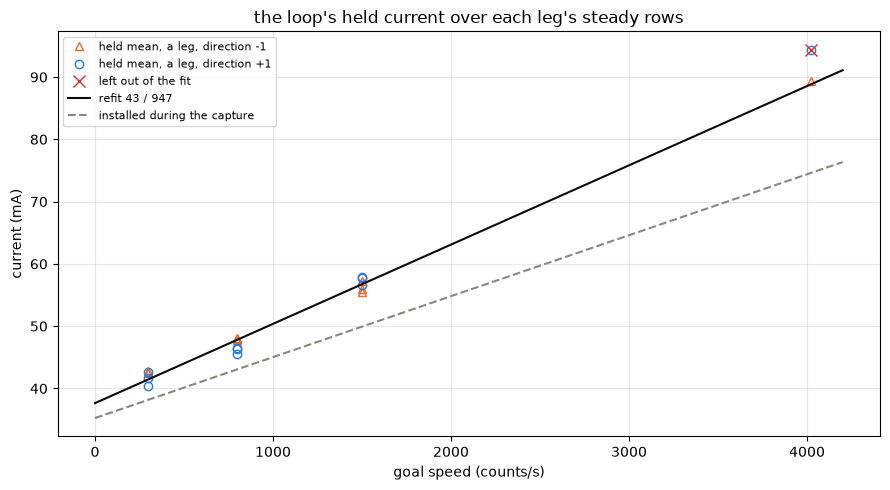

In [20]:
fig, ax = plt.subplots(figsize=(9, 5))
v = np.linspace(0, 4200, 50)
for d, grp in W.groupby("dir"):
    ax.plot(grp.goal, grp.held_ma, figures.DIRECTION_MARKER[d], ms=6,
            color=BLUE if d > 0 else ORANGE, mfc="none",
            label=f"held mean, a leg, direction {d:+d}")
out = W.drop(FIT_LEGS.index)
ax.plot(out.goal, out.held_ma, "x", ms=9, color=RED,
        label="left out of the fit")
ax.plot(v, I0 + SLOPE * v / 1e3, color=INK,
        label=f"refit {WORDS[0]} / {WORDS[1]}")
ax.plot(v, [line_ma(SITTING["g3"], x) for x in v], color=MUTED, ls="--",
        label="installed during the capture")
ax.legend(fontsize=8)
figures.label(ax, x="goal speed (counts/s)", y="current (mA)",
              title="the loop's held current over each leg's steady rows")
figures.finish(fig)

The one whole leg left out is the 4025 c/s up leg, still gaining speed, which sits 5.5 mA over the line. The half legs at 4025 are not whole and not drawn.

### The repeat on the refit words

`g3b` ran the same legs on 43 / 947. A feed-forward that is right moves the integrator to near zero and leaves the held mean where it was. The repeat's legs, then its grade by speed.

In [21]:
WB = LEGS["g3b"][LEGS["g3b"].whole].copy()
print(LEGS["g3b"][cols[:3] + ["leg_ms", "whole", "held_in_ms", "cps",
                              "v2_v1_pct", "sd_in_ma", "sd_worst_ma"]]
      .to_string(index=False, float_format=lambda v: f"{v:.2f}"))
GRADE = WB.groupby("goal").agg(legs=("seg", "size"),
                               integ=("integ_ma", "mean"),
                               integ_sd=("integ_ma", "std"),
                               held_less_line=("held_ma", "mean"),
                               read_share=("read_share", "mean"))
GRADE["held_less_line"] -= [line_ma(SITTING["g3b"], v)
                            for v in GRADE.index]
print(GRADE.to_string(float_format=lambda v: f"{v:+.2f}"))

capture  seg  dir  leg_ms  whole  held_in_ms     cps  v2_v1_pct  sd_in_ma  sd_worst_ma
   c300    0    1 1200.00   True      200.00  296.15      -5.38      0.36         3.19
   c300    1   -1 1200.00   True      200.00  302.65      -5.02      0.36         2.97
   c300    2    1 1200.00   True      200.00  299.49      -2.60      0.35         2.67
   c300    3   -1 1200.00   True      200.00  301.16      -1.07      0.35         3.08
   c300    4    1 1200.00   True      200.00  299.27      -7.15      0.35         2.67
   c300    5   -1 1200.00   True      200.00  299.27      -1.92      0.35         2.52
   c800    0    1 1200.00   True      525.00  788.77      -0.41      0.40         3.96
   c800    1   -1 1200.00   True      225.00  800.69      -0.90      0.38         3.73
   c800    2    1 1200.00   True      150.00  803.80      -1.18      0.37         4.00
   c800    3   -1 1200.00   True      150.00  801.96       1.47      0.39         3.79
   c800    4    1 1200.00   True      150.0

At 300 c/s the speed sagged 1 to 7 % across the steady rows of all six legs while holding the goal on average. At 4025 c/s the three down legs held 4020 c/s within 0.5 %, and the three up legs still gained 3.5 to 3.9 % across their steady rows, as the one up leg of `g3` did.

The lines the grade was written with before the repeat ran. The integrator's share within -2 to +7 mA at 300 c/s, where the loop sits at the floor's edge, and within +/-5 mA at 800 and 1500. The held mean within +/-4 mA of the line. Two falsifiers, all three shares of one sign beyond 4 mA (a level error), and 300 and 1500 c/s of opposite signs beyond 4 mA (a slope error).

In [22]:
BANDS = {300: (-2, 7), 800: (-5, 5), 1500: (-5, 5)}   # mA, the shares
HELD_BAND = 4                           # mA, the held mean from the line
for v, (lo, hi) in BANDS.items():
    i, h = GRADE.loc[v, "integ"], GRADE.loc[v, "held_less_line"]
    print(f"{v} c/s: integrator {i:+.2f} against {lo:+d} / {hi:+d}: "
          f"{'pass' if lo <= i <= hi else 'FAIL'}; held less line "
          f"{h:+.2f} against +/- {HELD_BAND}: "
          f"{'pass' if abs(h) <= HELD_BAND else 'FAIL'}")
three = GRADE.loc[list(BANDS), "integ"]
print("all three of one sign beyond 4 mA:",
      bool((three > 4).all() or (three < -4).all()))
print("300 and 1500 of opposite sign beyond 4 mA:",
      bool(abs(three[300]) > 4 and abs(three[1500]) > 4
           and np.sign(three[300]) != np.sign(three[1500])))
print(f"4025 c/s: integrator {GRADE.loc[4025, 'integ']:+.2f} mA over "
      f"{int(GRADE.loc[4025, 'legs'])} legs")

300 c/s: integrator -0.39 against -2 / +7: pass; held less line -0.41 against +/- 4: pass
800 c/s: integrator -0.96 against -5 / +5: pass; held less line -0.86 against +/- 4: pass
1500 c/s: integrator +0.92 against -5 / +5: pass; held less line +1.13 against +/- 4: pass
all three of one sign beyond 4 mA: False
300 and 1500 of opposite sign beyond 4 mA: False
4025 c/s: integrator +3.62 mA over 6 legs


Every clause passes, no share beyond 1 mA at 300 to 1500 c/s, and neither falsifier trips. At 4025 c/s the integrator carries +3.6 mA over six legs.

### Leg for leg

The two sittings ran the same schedule at 300 to 1500 c/s, so each leg of one pairs with the same leg of the other.

In [23]:
pair = W.merge(WB, on=["capture", "seg", "dir", "goal"], suffixes=("_a",
                                                                   "_b"))
pair = pair[pair.goal < 4000]
moved_held = pair.held_ma_b - pair.held_ma_a
moved_integ = pair.integ_ma_b - pair.integ_ma_a
print(f"{len(pair)} legs paired at 300 to 1500 c/s: held mean moved "
      f"{moved_held.min():+.2f} to {moved_held.max():+.2f} mA, the "
      f"integrator {moved_integ.min():+.2f} to {moved_integ.max():+.2f}")
both = pd.concat([W.assign(run="g3"), WB.assign(run="g3b")])
per = both.groupby(["goal", "run"])["held_ma"].agg(["mean", "sem"])
for v in sorted(both.goal.unique()):
    a, b = per.loc[(v, "g3")], per.loc[(v, "g3b")]
    dl = line_ma(SITTING["g3b"], v) - line_ma(SITTING["g3"], v)
    dh, se = b["mean"] - a["mean"], np.hypot(a["sem"], b["sem"])
    print(f"{v} c/s: held {a['mean']:.2f} -> {b['mean']:.2f} ({dh:+.2f} "
          f"+/- {se:.2f}), the line moved {dl:+.2f}")

18 legs paired at 300 to 1500 c/s: held mean moved -2.27 to +2.31 mA, the integrator -7.21 to -3.31
300 c/s: held 42.08 -> 41.29 (-0.79 +/- 0.48), the line moved +3.53
800 c/s: held 47.04 -> 47.21 (+0.17 +/- 0.75), the line moved +5.00
1500 c/s: held 56.82 -> 58.11 (+1.29 +/- 0.66), the line moved +7.06
4025 c/s: held 91.86 -> 92.72 (+0.86 +/- 2.58), the line moved +14.49


Across 18 pairs the held mean moved -2.3 to +2.3 mA and the integrator -3.3 to -7.2 mA, no pair the wrong way. By speed the held mean moved -0.8, +0.2, +1.3 and +0.9 mA while the line moved 3.5, 5.0, 7.1 and 14.5 mA. The 1500 c/s move is 2.0 sigma, at the threshold and no finding. The integrator took the rest.

The held mean and the integrator's share by speed in both sittings. The thing to see is the held means on top of each other and the shares falling to near zero.

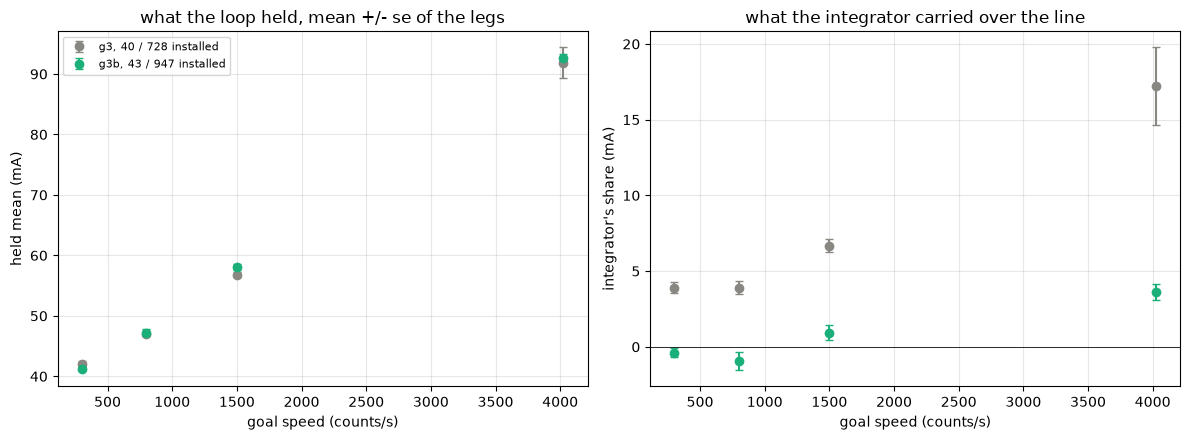

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for label, frame, color in (("g3, 40 / 728 installed", W, MUTED),
                            ("g3b, 43 / 947 installed", WB, GREEN)):
    s = frame.groupby("goal").agg(h=("held_ma", "mean"),
                                  h_se=("held_ma", "sem"),
                                  i=("integ_ma", "mean"),
                                  i_se=("integ_ma", "sem"))
    a1.errorbar(s.index, s.h, s.h_se, fmt="o", color=color, capsize=3,
                label=label)
    a2.errorbar(s.index, s.i, s.i_se, fmt="o", color=color, capsize=3,
                label=label)
a2.axhline(0, color=INK, lw=0.6)
a1.legend(fontsize=8)
figures.label(a1, x="goal speed (counts/s)", y="held mean (mA)",
              title="what the loop held, mean +/- se of the legs")
figures.label(a2, x="goal speed (counts/s)", y="integrator's share (mA)",
              title="what the integrator carried over the line")
figures.finish(fig)

### Both sittings together

Since the held mean did not move, the two sittings can be fitted together. The repeat's 4025 c/s legs are six whole legs of 600 ms against `g3`'s one steady leg, and its up legs gained speed across their steady rows, so each leg's held mean has the current its gain in speed costs through the inertia word taken off first.

In [25]:
MED_HZ = BOARD.tick_hz / cn.DECIM_MED   # MEDIUM periods a second


def inertia_ma(r):
    # the current a leg's gain in speed across its steady rows costs
    # through the stored inertia word
    dv = r.cps * (r.v2_v1_pct / 100) / (1 + r.v2_v1_pct / 200)
    return J_FF * dv / (r.rows / 2 / BOARD.tick_hz) / MED_HZ * MA


JOINT = both[(both.goal < 4000) | (both.run == "g3b")].copy()
JOINT["steady_ma"] = JOINT.held_ma - JOINT.apply(inertia_ma, axis=1)
J = results.fit_line(JOINT.goal / 1e3, JOINT.steady_ma)
JOINT_WORDS = (word(J["intercept"] / MA), word(J["slope"] / 1e3 / MA
                                                * 65536))
print(f"{len(JOINT)} legs: {J['intercept']:.2f} +/- "
      f"{J['intercept_se']:.2f} + {J['slope']:.3f} +/- {J['slope_se']:.3f}"
      f" per 1000 c/s -> {JOINT_WORDS[0]} / {JOINT_WORDS[1]}")
d4025 = (J["intercept"] + J["slope"] * 4.025) - (I0 + SLOPE * 4.025)
print(f"against the refit: {J['intercept'] - I0:+.2f} mA at 0 c/s, "
      f"{d4025:+.2f} mA at 4025 c/s")

42 legs: 36.97 +/- 0.28 + 13.623 +/- 0.160 per 1000 c/s -> 42 / 1013
against the refit: -0.67 mA at 0 c/s, +2.93 mA at 4025 c/s


The joint line, 42 / 1013, sits 0.67 mA under the refit at zero speed and 2.9 mA over it at 4025 c/s. It is the better number where the two differ, at the top of the line, which the refit takes from one leg. It is reported, and the refit stands, since it passes every clause of its grade.

## Results

The loop's held current under the window term is 37.64 +/- 0.40 mA + 12.73 +/- 0.30 mA per 1000 c/s from 300 to 4025 c/s, `fric_fc_counts` 43 and `fric_fv_q016` 947 on the set's scale. The repeat on those words left the integrator within 1 mA of zero at 300 to 1500 c/s and at +3.6 mA at 4025. The result file's quantities. The slope is also given per motor rad/s, so a rule can carry it to any table.

In [26]:
q, pm = results.quantity, results.pm
OUT = {
    "coulomb_ma": pm(I0, LINE["intercept_se"], "mA, the line's intercept: "
                     "the loop's held current at zero speed, se bounds"),
    "viscous_ma_per_kcps": pm(SLOPE, LINE["slope_se"], "mA per 1000 count"
                              "/s of the set's table, se bounds"),
    "viscous_ma_s_per_rad": pm(SLOPE / 1e3 * COUNTS_PER_MOTOR_RAD,
                               LINE["slope_se"] / 1e3
                               * COUNTS_PER_MOTOR_RAD, "mA per motor "
                               "rad/s, the same slope at the table's "
                               "counts per degree and the gear ratio"),
    "counts_per_motor_rad": q(COUNTS_PER_MOTOR_RAD, unit="table counts a "
                              "motor radian the slope was converted at"),
    "rms_ma": q(LINE["rms"], unit="mA, the line's residual rms"),
    "legs": q(len(FIT_LEGS), unit="legs fitted"),
    "window_field_q016": q(FIELD, unit="g_window_q016 the cruises ran on"),
    "fric_fc_counts": q(WORDS[0], unit="the intercept in shunt counts, "
                        "report: the set's rule gives the field"),
    "fric_fv_q016": q(WORDS[1], unit="the slope in Q0.16 shunt counts per "
                      "count/s, report"),
}

In [27]:
OUT["held_ma"] = {str(v): pm(r["mean"], r["sem"], "mA, held mean of "
                             "the whole legs, se") for v, r in held.iterrows()}
OUT["residual_ma"] = {
    str(v): pm(r["mean"], r["sem"], "mA, the legs' residual, se")
    if r["size"] > 1 else q(r["mean"], unit="mA, the one leg's residual")
    for v, r in res.agg(["size", "mean", "sem"]).iterrows()}
OUT["integrator_installed_ma"] = {
    str(v): q(x, unit="mA, the integrator's share on the line installed "
              "during the capture (40 / 728)") for v, x in
    W.groupby("goal")["integ_ma"].mean().items()}
OUT["integrator_refit_ma"] = {
    str(v): pm(r["integ"], r["integ_sd"], "mA, the integrator's share on "
               "the refit words in the repeat, sd over legs")
    for v, r in GRADE.iterrows()}
OUT["joint_coulomb_ma"] = pm(J["intercept"], J["intercept_se"], "mA, "
                             "both sittings with the repeat's 4025 legs, "
                             "each leg's inertia current off, report")
OUT["joint_viscous_ma_per_kcps"] = pm(J["slope"], J["slope_se"], "mA per "
                                      "1000 count/s, the same, report")

### The result file

The notes that define every key, then the file as written.

In [28]:
NOTES = (
    "stage 5 cruise friction of mg90-d on dev-v006-2A-D: the friction line "
    "the velocity loop holds under the window term, from window-term/g3 "
    "(Velocity cruises at 300, 800, 1500 and 4025 c/s, both ways, "
    "g_window_q016 at the window-term result's field, friction 40 / 728 "
    "installed) and its repeat window-term/g3b on the refit words. Each "
    "leg's current-loop reference is replayed from its rows with the "
    "board's integer reading (settle gain, window term, the polled bias) "
    "and the set of record's loop gains and Ke; the held mean is the "
    "reading on read rows and the reference, averaged over its MEDIUM "
    "period, on the rest, over the leg's middle half. The line is a least "
    "squares fit of the held mean of the 18 whole legs at 300 to 1500 c/s "
    "and the one 4025 c/s leg whose speed held within 2 % across its "
    "steady rows, against the goal; coulomb_ma and viscous_ma_s_per_rad "
    "are what the set's rules read, the words report only. The repeat on "
    "the refit words grades it; the joint_* keys are both sittings fitted "
    "together, report only."
)
CAPTURE = ", ".join(str(results.rel(p)) for p in RUNS.values())
path = results.write("5-closed-loop", "cruise-friction", CAPTURE, pair=PAIR,
                     notes=NOTES, **OUT)
written = results.read("5-closed-loop", "cruise-friction", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys")
flat = pd.DataFrame([{"key": k, **v} for k, v in written.items()
                     if isinstance(v, dict) and "value" in v])
show(flat, n=None)

wrote stages/5-closed-loop/cruise-friction/results/mg90-d__dev-v006-2A-D.json with 15 keys


,key,value,lo,hi,unit
0,coulomb_ma,37.642,37.240,38.044,"mA, the line's intercept: the loop's held curr..."
1,viscous_ma_per_kcps,12.728,12.428,13.028,"mA per 1000 count/s of the set's table, se bounds"
2,viscous_ma_s_per_rad,0.048,0.047,0.049,"mA per motor rad/s, the same slope at the tabl..."
3,counts_per_motor_rad,3.743,NaN,NaN,table counts a motor radian the slope was conv...
4,rms_ma,1.055,NaN,NaN,"mA, the line's residual rms"
5,legs,19.000,NaN,NaN,legs fitted
6,window_field_q016,1178.000,NaN,NaN,g_window_q016 the cruises ran on
7,fric_fc_counts,43.000,NaN,NaN,"the intercept in shunt counts, report: the set..."
8,fric_fv_q016,947.000,NaN,NaN,"the slope in Q0.16 shunt counts per count/s, r..."
9,joint_coulomb_ma,36.973,36.689,37.257,"mA, both sittings with the repeat's 4025 legs,..."


## Limitations

- One capture a speed for the fit and one for the repeat, ten minutes apart, one rail, one temperature. The spread from day to day is not measured, and the line's standard errors, 0.40 mA and 0.30 mA per 1000 c/s, are inside one sitting.
- The top of the line rests on one 4025 c/s leg of 250 ms of steady rows.
- The rows carry no integrator. The held mean and the integrator's share come from one replay, so the held mean less the integrator and the line is not an independent check.
- The line rides the window field the cruises ran on. A refit of the window term moves the held mean and with it the line's level.
- The line is the loop's held current, not the drag as a torque. It matches the drag only where every tick is read, at 4025 c/s here.

## Open discrepancies

1. The up legs at 4025 c/s gain 3.5 to 5.6 % across their steady rows in both sittings, and the down legs do not. Candidates are a loop that settles slower in that direction at the top speed, a drag that differs by direction there, and the runway at the up end. Legs of 900 ms or more, three each way, from the same starts and from starts moved by a third of the travel, separate them.
2. The joint fit of both sittings against the refit, 2.9 mA apart at 4025 c/s. Candidates are the refit's top resting on one leg (leading) and a drift between the sittings. The longer 4025 legs of item 1 on the refit words decide it, since the integrator's share there would be about +3 mA on the refit and about 0 on the joint line.
3. Reverse legs hold 1.1 and 1.9 mA more than forward ones at 300 and 800 c/s and 1.2 mA less at 1500. Candidates are stage 1's direction offset of the current chain (1.2 counts, about 1 mA) and a drag that differs by direction in the train. The same cruises with the motor's leads swapped at the board separate them, since the chain's part follows the board and the train's follows the horn.
4. The replay is the only source of the reference and the integrator. A capture whose rows carry the integrator and the loop's own current, at the same speeds, checks it directly.

## Conclusion

Under the window term at the window-term notebook's field, one line holds the velocity loop's held current on mg90-d from 300 to 4025 c/s within 1 mA by speed, 37.64 mA + 12.73 mA per 1000 c/s, `fric_fc_counts` 43 and `fric_fv_q016` 947. A repeat on those words left the integrator within 1 mA of zero at 300 to 1500 c/s and the held mean where it was, so the line is right in form and level there. Its top at 4025 c/s is good to about 3 mA. It stands only with the window field it was measured under, and moves with it.